# Lab Task 04 – Geometric Transformations with Custom Inputs

**Name:** Kamal Ali Akmal  **Roll No:** 2024-SE-38  
**Course:** Digital Image Processing Lab – Department of Software Engineering, UAJK  
**Instructor:** Engr. Fahad Nisar | **Semester:** 5th | **Session:** 2024-28 (SE)

**Objective:** build one reusable `transform(image, operation, **params)` function that performs scaling, cropping, flipping, translation and rotation with custom, validated inputs.

**Libraries:** NumPy, OpenCV (`cv2`) and Matplotlib. Run with *Kernel → Restart & Run All*.

## 1. Configuration, loading and validating the image

**Colour handling:** OpenCV reads images as **BGR**. The image is converted to **RGB once, right after loading**; every operation and every Matplotlib display uses RGB, and conversion back to BGR happens only when a file is saved. The original array is made *read-only* so no operation can change it, and it is compared with a backup copy at the end.

Loaded 'input_image.png'
Width = 640, Height = 480
Array shape = (480, 640, 3)  (rows=height, columns=width, channels)   dtype = uint8


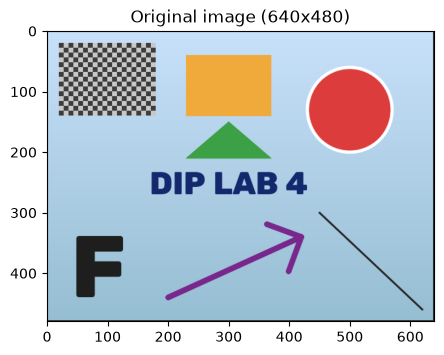

In [16]:
import math, numbers, os
import numpy as np
import cv2
import matplotlib.pyplot as plt

IMAGE_PATH = "input_image.png"     # replace with your own image if you wish
OUTPUT_DIR = "outputs"             # transformed images are saved here
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Declared limits (enforced inside transform)
MAX_SIDE   = 4000        # output width or height may not exceed 4000 px
MAX_PIXELS = 12_000_000  # output width * height may not exceed 12 megapixels
MAX_OFFSET = 4000        # |tx| and |ty| may not exceed 4000 px (beyond that the picture is always fully off-canvas)

def load_image(path):
    """Load an image as an RGB uint8 array; fail clearly if the file is missing, undecodable or empty."""
    if not isinstance(path, str) or not os.path.isfile(path):
        raise FileNotFoundError(f"Image file not found: {path!r}")
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)           # returns None if decoding fails
    if bgr is None:
        raise ValueError(f"File exists but could not be decoded as an image: {path!r}")
    if bgr.ndim != 3 or bgr.shape[0] == 0 or bgr.shape[1] == 0:
        raise ValueError("Image has zero width or height")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

original = load_image(IMAGE_PATH)
original_backup = original.copy()      # used at the end to prove the original was never modified
original.flags.writeable = False       # any accidental in-place change would raise an error

height, width = original.shape[:2]
print(f"Loaded {IMAGE_PATH!r}")
print(f"Width = {width}, Height = {height}")
print(f"Array shape = {original.shape}  (rows=height, columns=width, channels)   dtype = {original.dtype}")

plt.figure(figsize=(5, 4))
plt.imshow(original); plt.title(f"Original image ({width}x{height})")
plt.show()

## 2. The reusable `transform` function

`transform(image, operation, **params)` is the **single entry point**. Nothing is hard-coded inside it; every value arrives as an argument.

| operation | required parameters |
|---|---|
| `"scale"` | `sx`, `sy`, `interpolation` (`nearest`, `bilinear`, `bicubic`, `lanczos`) |
| `"crop"` | `left`, `top`, `right`, `bottom` (integers, right/bottom exclusive) |
| `"flip"` | `direction` (`horizontal`, `vertical`, `both`) |
| `"translate"` | `tx`, `ty` (pixels, any finite sign) |
| `"rotate"` | `angle` (degrees, any finite value), `expand` (`True`/`False`) |

**Validation inside `transform`:** unknown operation, missing or unexpected parameters, non-numbers, NaN/infinity, non-integer crop coordinates, invalid crop regions, unsupported interpolation/direction, empty output (< 1 px) and output larger than the declared limits are all rejected with a `TransformError`. No default values are substituted. Zero offsets, zero angles and negative offsets/angles are valid.

**Conventions:** translation and rotation keep/fill exposed areas with **black**; positive `tx` moves right, positive `ty` moves down, and a **positive angle rotates counter-clockwise** as seen on screen, about the image centre.

In [17]:
INTERPOLATIONS = {"nearest": cv2.INTER_NEAREST, "bilinear": cv2.INTER_LINEAR,
                  "bicubic": cv2.INTER_CUBIC,   "lanczos": cv2.INTER_LANCZOS4}
FLIP_CODES = {"horizontal": 1, "vertical": 0, "both": -1}
REQUIRED_PARAMS = {
    "scale":     {"sx", "sy", "interpolation"},
    "crop":      {"left", "top", "right", "bottom"},
    "flip":      {"direction"},
    "translate": {"tx", "ty"},
    "rotate":    {"angle", "expand"},
}

class TransformError(ValueError):
    """Raised for any invalid operation, parameter or output size."""

# ---------- validation helpers ----------
def _check_image(image):
    if not isinstance(image, np.ndarray):
        raise TransformError("image must be a NumPy array")
    if image.dtype != np.uint8 or image.ndim != 3 or image.shape[2] != 3:
        raise TransformError("image must be a uint8 array of shape (height, width, 3)")
    if image.shape[0] < 1 or image.shape[1] < 1:
        raise TransformError("image has zero width or height")

def _number(name, value):
    """Return value as a finite float, rejecting bool, text, NaN and infinity."""
    if isinstance(value, (bool, np.bool_)) or not isinstance(value, numbers.Real):
        raise TransformError(f"{name} must be a number, got {value!r}")
    try:
        value = float(value)
    except OverflowError:
        raise TransformError(f"{name} is too large to be used")
    if not math.isfinite(value):
        raise TransformError(f"{name} must be finite (NaN and infinity are not allowed), got {value}")
    return value

def _integer(name, value):
    value = _number(name, value)
    if not value.is_integer():
        raise TransformError(f"{name} must be a whole number, got {value}")
    return int(value)

def _choice(name, value, allowed):
    if not isinstance(value, str) or value.strip().lower() not in allowed:
        raise TransformError(f"{name} must be one of {list(allowed)}, got {value!r}")
    return value.strip().lower()

def _check_output_size(out_w, out_h):
    if out_w < 1 or out_h < 1:
        raise TransformError(f"output would be {out_w}x{out_h}; both dimensions must be at least 1 pixel")
    if out_w > MAX_SIDE or out_h > MAX_SIDE or out_w * out_h > MAX_PIXELS:
        raise TransformError(f"output {out_w}x{out_h} exceeds the limit (max side {MAX_SIDE}px, max {MAX_PIXELS:,} pixels)")

# ---------- the five operations ----------
def _scale(image, sx, sy, interpolation):
    sx, sy = _number("sx", sx), _number("sy", sy)
    if sx <= 0 or sy <= 0:
        raise TransformError(f"scale factors must be greater than zero, got sx={sx}, sy={sy}")
    method = INTERPOLATIONS[_choice("interpolation", interpolation, INTERPOLATIONS)]
    h, w = image.shape[:2]
    fw, fh = w * sx, h * sy
    if not (math.isfinite(fw) and math.isfinite(fh)):
        raise TransformError("scale factors are too large")
    out_w, out_h = int(round(fw)), int(round(fh))        # integer output dimensions
    _check_output_size(out_w, out_h)
    return cv2.resize(image, (out_w, out_h), interpolation=method)

def _crop(image, left, top, right, bottom):
    left, top = _integer("left", left), _integer("top", top)
    right, bottom = _integer("right", right), _integer("bottom", bottom)
    h, w = image.shape[:2]
    if not (0 <= left < right <= w):
        raise TransformError(f"invalid horizontal range: need 0 <= left < right <= {w}, got left={left}, right={right}")
    if not (0 <= top < bottom <= h):
        raise TransformError(f"invalid vertical range: need 0 <= top < bottom <= {h}, got top={top}, bottom={bottom}")
    return image[top:bottom, left:right].copy()          # right and bottom are exclusive

def _flip(image, direction):
    direction = _choice("direction", direction, FLIP_CODES)
    return cv2.flip(image, FLIP_CODES[direction])

def _translate(image, tx, ty):
    tx, ty = _number("tx", tx), _number("ty", ty)
    if abs(tx) > MAX_OFFSET or abs(ty) > MAX_OFFSET:
        raise TransformError(f"offsets must satisfy |t| <= {MAX_OFFSET}, got tx={tx}, ty={ty}")
    h, w = image.shape[:2]
    M = np.float64([[1, 0, tx], [0, 1, ty]])
    return cv2.warpAffine(image, M, (w, h), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))   # same canvas size

def _rotate(image, angle, expand):
    angle = _number("angle", angle)
    if not isinstance(expand, (bool, np.bool_)):
        raise TransformError(f"expand must be True or False, got {expand!r}")
    h, w = image.shape[:2]
    cx, cy = (w - 1) / 2, (h - 1) / 2                      # centre of the image (pixel-centre coordinates)
    a = angle % 360.0
    M = cv2.getRotationMatrix2D((cx, cy), a, 1.0)          # positive angle = counter-clockwise
    out_w, out_h = w, h
    if expand:                                             # bounding box of the rotated rectangle
        c, s = abs(math.cos(math.radians(a))), abs(math.sin(math.radians(a)))
        out_w = int(math.ceil(w * c + h * s - 1e-9))
        out_h = int(math.ceil(w * s + h * c - 1e-9))
        _check_output_size(out_w, out_h)
        M[0, 2] += (out_w - 1) / 2 - cx                    # move the centre to the centre of the new canvas
        M[1, 2] += (out_h - 1) / 2 - cy
    return cv2.warpAffine(image, M, (out_w, out_h), flags=cv2.INTER_LINEAR,
                          borderMode=cv2.BORDER_CONSTANT, borderValue=(0, 0, 0))

_DISPATCH = {"scale": _scale, "crop": _crop, "flip": _flip, "translate": _translate, "rotate": _rotate}

def transform(image, operation, **params):
    """Apply `operation` to `image` using the custom `params`; returns a NEW image (input is never modified)."""
    _check_image(image)
    if not isinstance(operation, str) or operation.strip().lower() not in REQUIRED_PARAMS:
        raise TransformError(f"unknown operation {operation!r}; choose from {list(REQUIRED_PARAMS)}")
    op = operation.strip().lower()
    missing = REQUIRED_PARAMS[op] - params.keys()
    extra = params.keys() - REQUIRED_PARAMS[op]
    if missing:
        raise TransformError(f"'{op}' is missing required parameter(s): {sorted(missing)}")
    if extra:
        raise TransformError(f"'{op}' got unexpected parameter(s): {sorted(extra)}")
    return _DISPATCH[op](image, **params)

# ---------- text input layer (user-typed text -> typed values) ----------
PARAM_SPECS = {   # (parameter name, kind, prompt text)
    "scale":     [("sx", "float", "Horizontal scale factor sx (>0)"),
                  ("sy", "float", "Vertical scale factor sy (>0)"),
                  ("interpolation", "choice", "Interpolation (nearest/bilinear/bicubic/lanczos)")],
    "crop":      [("left", "int", "left (x, inclusive)"), ("top", "int", "top (y, inclusive)"),
                  ("right", "int", "right (x, exclusive)"), ("bottom", "int", "bottom (y, exclusive)")],
    "flip":      [("direction", "choice", "Direction (horizontal/vertical/both)")],
    "translate": [("tx", "float", "Horizontal offset tx in pixels (+ = right)"),
                  ("ty", "float", "Vertical offset ty in pixels (+ = down)")],
    "rotate":    [("angle", "float", "Angle in degrees (+ = counter-clockwise)"),
                  ("expand", "bool", "Expand canvas to fit the whole rotated image? (yes/no)")],
}

def parse_value(kind, text, name):
    """Convert typed text into a number/bool. Choices are passed on and validated inside transform()."""
    text = str(text).strip()
    if kind == "float":
        try:
            v = float(text)
        except ValueError:
            raise TransformError(f"{name}: {text!r} is not a number")
        if not math.isfinite(v):
            raise TransformError(f"{name}: NaN and infinity are not allowed")
        return v
    if kind == "int":
        try:
            return int(text)
        except ValueError:
            raise TransformError(f"{name}: {text!r} is not a whole number")
    if kind == "bool":
        t = text.lower()
        if t in ("yes", "y", "true", "1"):  return True
        if t in ("no", "n", "false", "0"):  return False
        raise TransformError(f"{name}: please answer yes or no, got {text!r}")
    return text

def apply_from_text(image, operation, raw):
    """Parse a dict of typed strings and call transform (used by the rejected-input demonstrations)."""
    op = str(operation).strip().lower()
    if op not in PARAM_SPECS:
        return transform(image, operation, **raw)
    kinds = {n: k for n, k, _ in PARAM_SPECS[op]}
    parsed = {n: parse_value(kinds.get(n, "choice"), v, n) for n, v in raw.items()}
    return transform(image, operation, **parsed)

# ---------- display / save helpers ----------
def describe(params):
    return ", ".join(f"{k}={v}" for k, v in params.items())

def save_image(img, filename):
    path = os.path.join(OUTPUT_DIR, filename)
    if not cv2.imwrite(path, cv2.cvtColor(img, cv2.COLOR_RGB2BGR)):      # RGB -> BGR only when saving
        raise IOError(f"could not write {path}")
    print("saved ->", path)

def show_pair(orig, result, op, params, save_as=None):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
    axes[0].imshow(orig)
    axes[0].set_title(f"Original\n{orig.shape[1]}x{orig.shape[0]}", fontsize=10)
    axes[1].imshow(result)
    axes[1].set_title(f"{op}({describe(params)})\noutput {result.shape[1]}x{result.shape[0]}", fontsize=10)
    plt.tight_layout(); plt.show()
    if save_as:
        save_image(result, save_as)

def demo(op, save_as, **params):
    result = transform(original, op, **params)
    show_pair(original, result, op, params, save_as)
    return result

print("transform() ready. Operations:", list(REQUIRED_PARAMS))

transform() ready. Operations: ['scale', 'crop', 'flip', 'translate', 'rotate']


## 3. User-selected operation and parameters (notebook prompts)

`run_session` asks the user for an operation, then for each of its parameters, converts the typed text and passes the values to `transform`. A typed mistake (e.g. `abc`, `nan`, `10.5` for a crop coordinate) or an invalid combination (e.g. `right <= left`) prints a clear error and asks again – there is no crash and no silent default.

* Set `INTERACTIVE = True` and run the cell to type your own values (enter `q` to finish).
* With `INTERACTIVE = False` the cell replays a **scripted list of typed answers** (including deliberate mistakes) so the saved notebook shows a complete run.

Operation [scale/crop/flip/translate/rotate, q = quit]: rotate
  Angle in degrees (+ = counter-clockwise): abc
  ERROR: angle: 'abc' is not a number  -> try again
  Angle in degrees (+ = counter-clockwise): -30
  Expand canvas to fit the whole rotated image? (yes/no): maybe
  ERROR: expand: please answer yes or no, got 'maybe'  -> try again
  Expand canvas to fit the whole rotated image? (yes/no): yes
  OK: rotate(angle=-30.0, expand=True) -> output 795x736


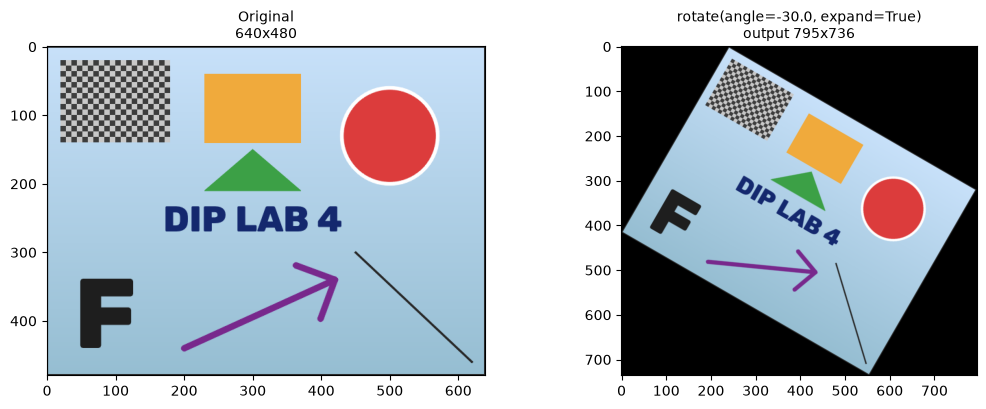

saved -> outputs\interactive_1_rotate.png
Operation [scale/crop/flip/translate/rotate, q = quit]: crop
  left (x, inclusive): 10.5
  ERROR: left: '10.5' is not a whole number  -> try again
  left (x, inclusive): 100
  top (y, inclusive): 50
  right (x, exclusive): 80
  bottom (y, exclusive): 300
  ERROR: invalid horizontal range: need 0 <= left < right <= 640, got left=100, right=80  -> please enter the values again
  left (x, inclusive): 100
  top (y, inclusive): 50
  right (x, exclusive): 420
  bottom (y, exclusive): 330
  OK: crop(left=100, top=50, right=420, bottom=330) -> output 320x280


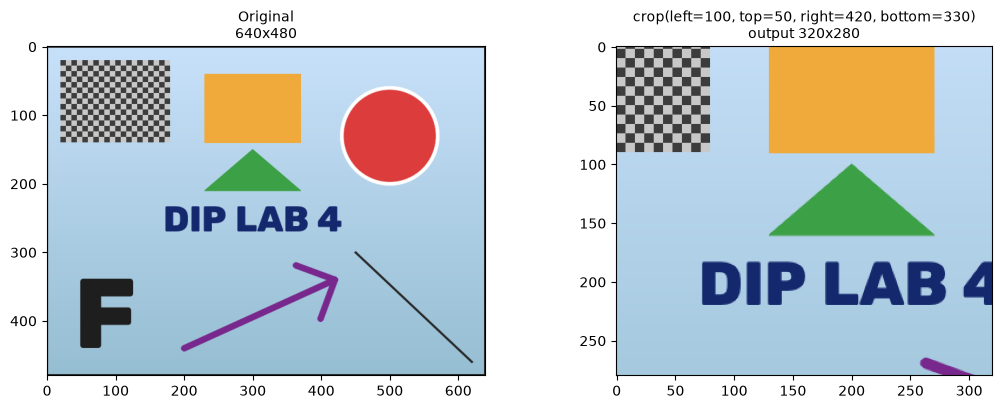

saved -> outputs\interactive_2_crop.png
Operation [scale/crop/flip/translate/rotate, q = quit]: flip
  Direction (horizontal/vertical/both): diagonal
  ERROR: direction must be one of ['horizontal', 'vertical', 'both'], got 'diagonal'  -> please enter the values again
  Direction (horizontal/vertical/both): both
  OK: flip(direction=both) -> output 640x480


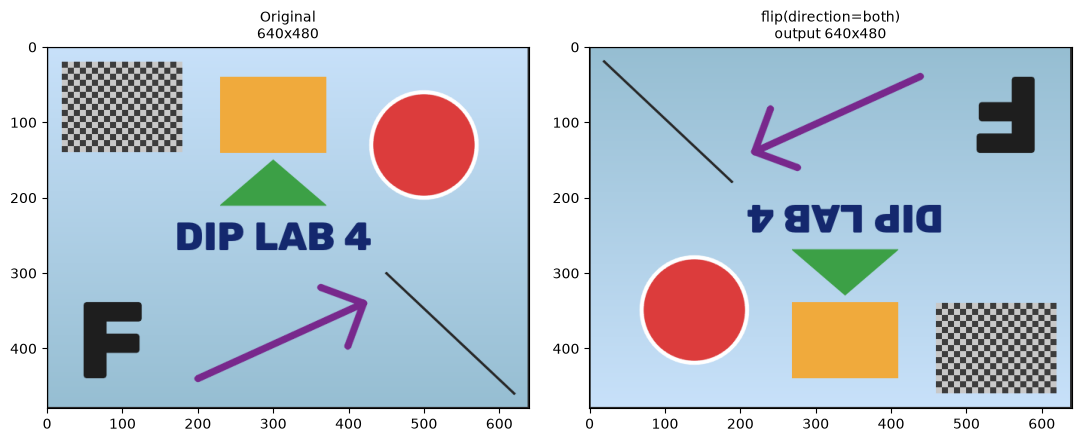

saved -> outputs\interactive_3_flip.png
Operation [scale/crop/flip/translate/rotate, q = quit]: scale
  Horizontal scale factor sx (>0): 1.5
  Vertical scale factor sy (>0): 0.75
  Interpolation (nearest/bilinear/bicubic/lanczos): lanczos
  OK: scale(sx=1.5, sy=0.75, interpolation=lanczos) -> output 960x360


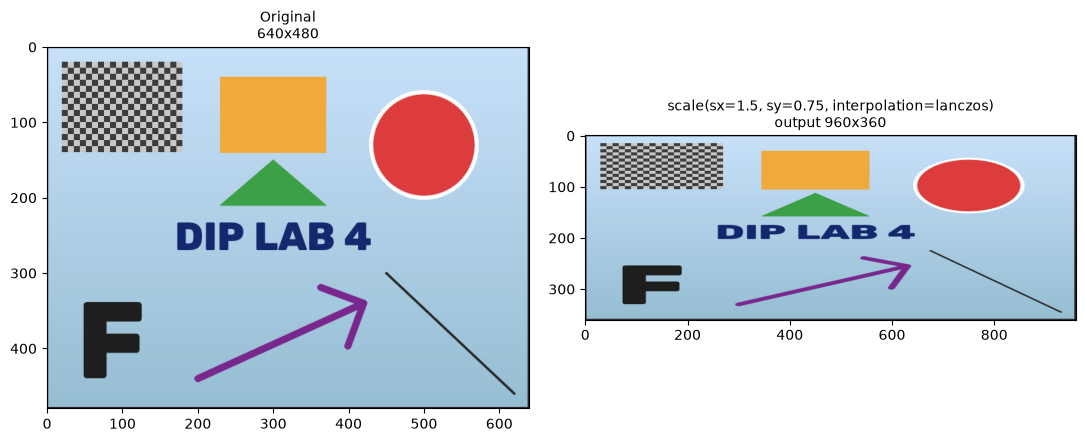

saved -> outputs\interactive_4_scale.png
Operation [scale/crop/flip/translate/rotate, q = quit]: translate
  Horizontal offset tx in pixels (+ = right): -40
  Vertical offset ty in pixels (+ = down): 25
  OK: translate(tx=-40.0, ty=25.0) -> output 640x480


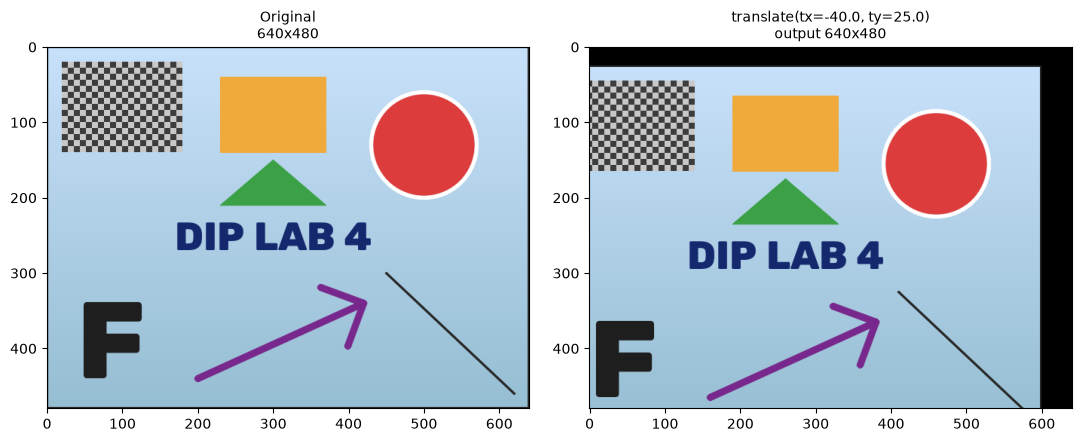

saved -> outputs\interactive_5_translate.png
Operation [scale/crop/flip/translate/rotate, q = quit]: q


In [18]:
INTERACTIVE = False        # True -> type your own answers with input()
SCRIPTED_ANSWERS = [
    "rotate", "abc", "-30", "maybe", "yes",                 # bad angle, bad yes/no, then valid
    "crop", "10.5", "100", "50", "80", "300",               # 10.5 not whole; then right(80) <= left(100)
            "100", "50", "420", "330",                      # corrected region
    "flip", "diagonal", "both",                             # unsupported direction, then valid
    "scale", "1.5", "0.75", "lanczos",
    "translate", "-40", "25",
    "q",
]
_answers = list(SCRIPTED_ANSWERS)

def ask(prompt):
    if INTERACTIVE:
        return input(prompt).strip()
    if not _answers:
        raise EOFError
    answer = _answers.pop(0)
    print(f"{prompt}{answer}")
    return answer

def run_session(image, prefix="interactive"):
    results = []
    try:
        while True:
            op = ask("Operation [scale/crop/flip/translate/rotate, q = quit]: ").lower()
            if op == "q":
                break
            if op not in PARAM_SPECS:
                print(f"  ERROR: unknown operation {op!r}")
                continue
            while True:                                           # repeat until the operation succeeds
                raw = {}
                for name, kind, desc in PARAM_SPECS[op]:
                    while True:
                        try:
                            raw[name] = parse_value(kind, ask(f"  {desc}: "), name)
                            break
                        except TransformError as err:
                            print(f"  ERROR: {err}  -> try again")
                try:
                    result = transform(image, op, **raw)
                except TransformError as err:
                    print(f"  ERROR: {err}  -> please enter the values again")
                    continue
                break
            print(f"  OK: {op}({describe(raw)}) -> output {result.shape[1]}x{result.shape[0]}")
            show_pair(image, result, op, raw, save_as=f"{prefix}_{len(results) + 1}_{op}.png")
            results.append((op, raw, result))
    except (EOFError, KeyboardInterrupt):
        print("(input ended)")
    return results

session_results = run_session(original)

## 4. Demonstration of every operation with custom values

### 4.1 Scaling – enlargement, reduction and non-proportional scaling
Output size = `round(width × sx)` × `round(height × sy)`. Equal factors keep the aspect ratio; different factors stretch one direction more than the other.

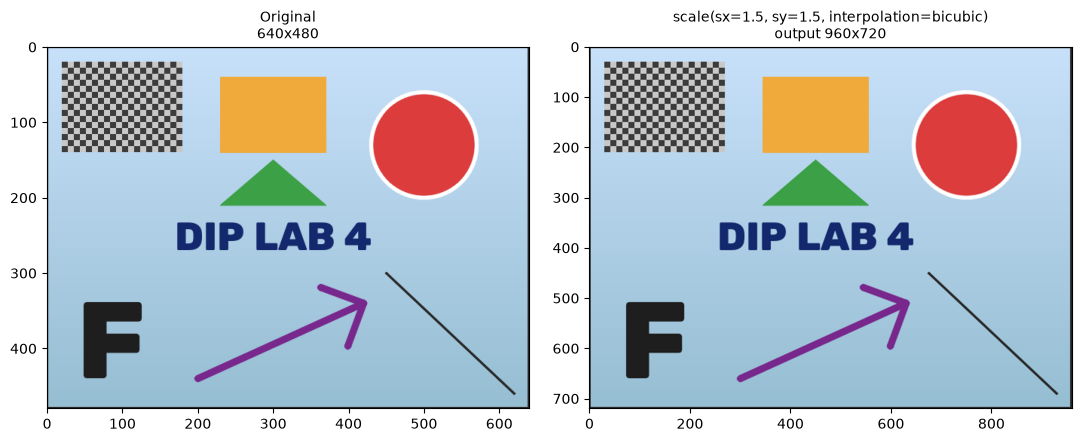

saved -> outputs\scale_enlarge_1.5x_bicubic.png


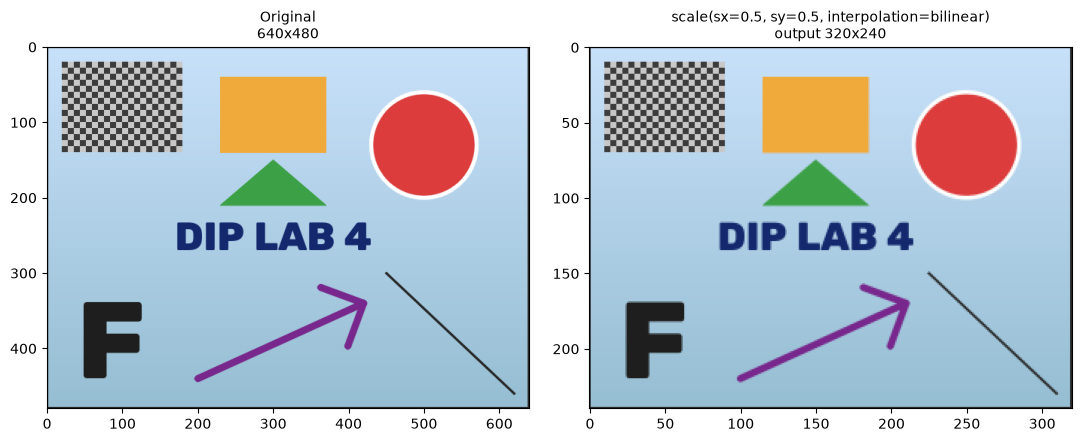

saved -> outputs\scale_reduce_0.5x_bilinear.png


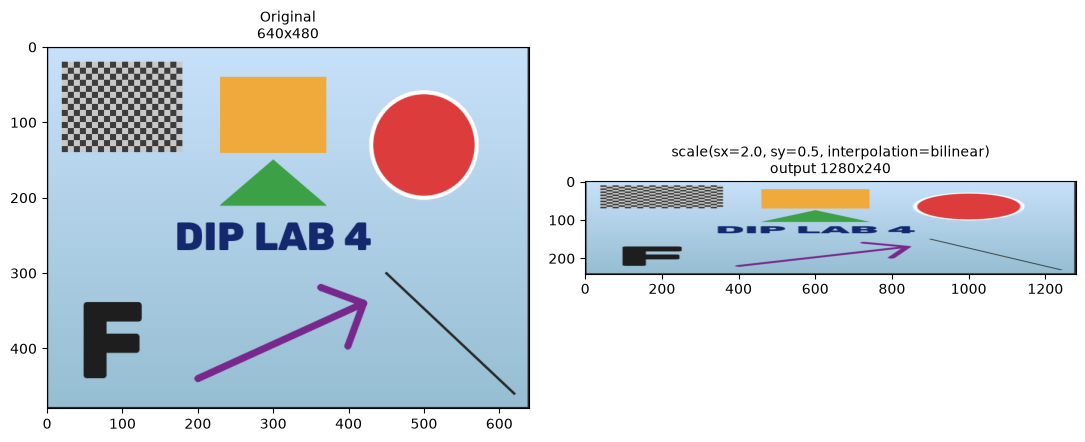

saved -> outputs\scale_nonproportional_2x_0.5y.png


In [19]:
r_big  = demo("scale", "scale_enlarge_1.5x_bicubic.png",   sx=1.5, sy=1.5, interpolation="bicubic")      # enlargement
r_small = demo("scale", "scale_reduce_0.5x_bilinear.png",  sx=0.5, sy=0.5, interpolation="bilinear")     # reduction
r_nonp = demo("scale", "scale_nonproportional_2x_0.5y.png", sx=2.0, sy=0.5, interpolation="bilinear")    # non-proportional

**Observation:** the 1.5× result is larger (960×720) and the 0.5× result is smaller (320×240); both keep the picture's proportions (circle stays a circle). With `sx=2.0, sy=0.5` the output is 1280×240: the circle becomes a wide ellipse and the letter *F* is squashed – this is **aspect-ratio distortion**, caused by unequal horizontal and vertical factors.

### 4.2 Cropping
Coordinates are `(left, top)` inclusive and `(right, bottom)` exclusive, so the output size is `(right-left) × (bottom-top)`.

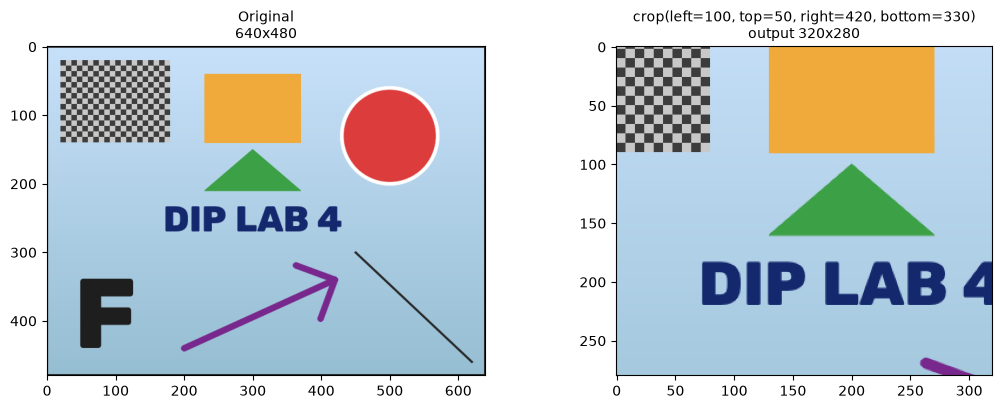

saved -> outputs\crop_left100_top50_right420_bottom330.png


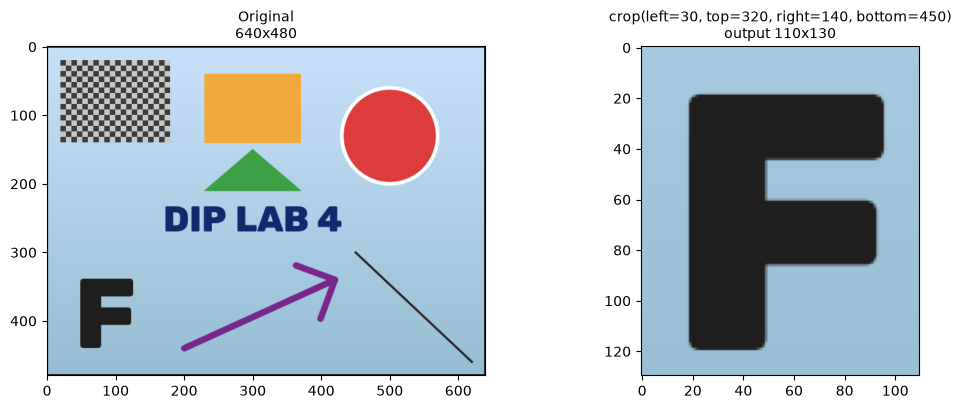

saved -> outputs\crop_letterF.png


In [20]:
r_crop1 = demo("crop", "crop_left100_top50_right420_bottom330.png", left=100, top=50, right=420, bottom=330)
r_crop2 = demo("crop", "crop_letterF.png", left=30, top=320, right=140, bottom=450)

**Observation:** the first crop is 320×280 pixels (420−100 by 330−50) and the second isolates the letter *F* (110×130). Because `right` and `bottom` are exclusive, the pixel at column 420 / row 330 is not included.

### 4.3 Flipping – all three directions

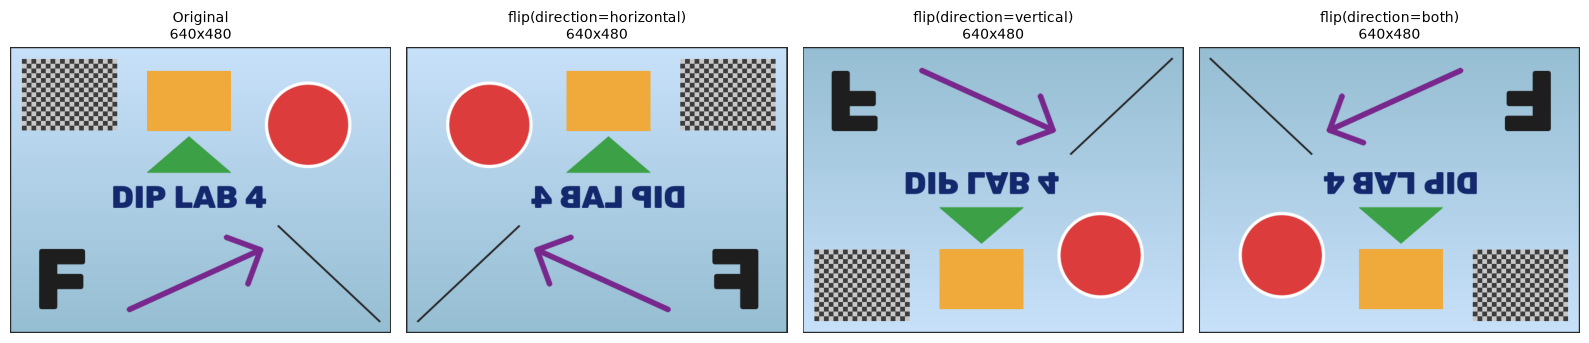

saved -> outputs\flip_horizontal.png
saved -> outputs\flip_vertical.png
saved -> outputs\flip_both.png


In [21]:
flips = {d: transform(original, "flip", direction=d) for d in ("horizontal", "vertical", "both")}
fig, axes = plt.subplots(1, 4, figsize=(16, 3.6))
for ax, (title, img) in zip(axes, [("Original", original)] + [(f"flip(direction={d})", im) for d, im in flips.items()]):
    ax.imshow(img); ax.set_title(f"{title}\n{img.shape[1]}x{img.shape[0]}", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()
for d, im in flips.items():
    save_image(im, f"flip_{d}.png")

**Observation:** `horizontal` mirrors left↔right (the *F* faces backwards), `vertical` mirrors top↔bottom (upside-down), and `both` equals a 180° rotation. Size never changes.

### 4.4 Translation – shifts in opposite directions
`tx>0` moves the image right, `ty>0` moves it down. The canvas stays 640×480.

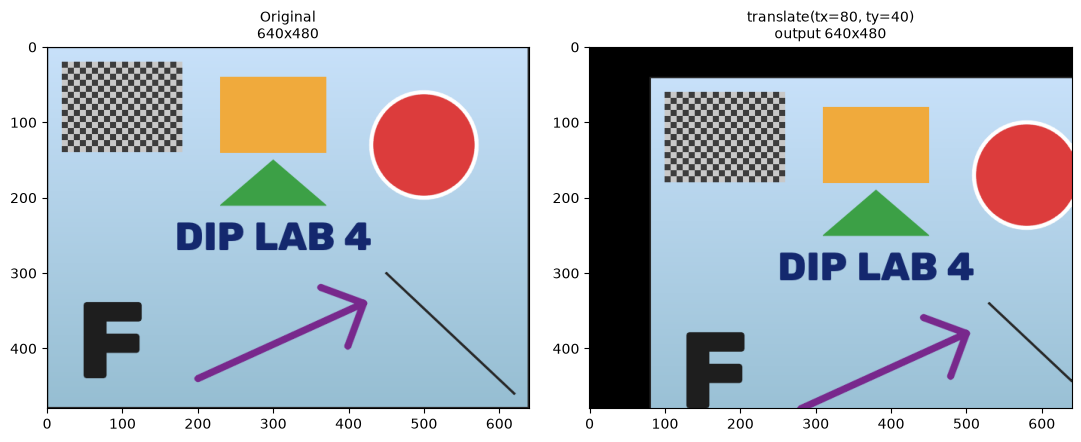

saved -> outputs\translate_tx80_ty40.png


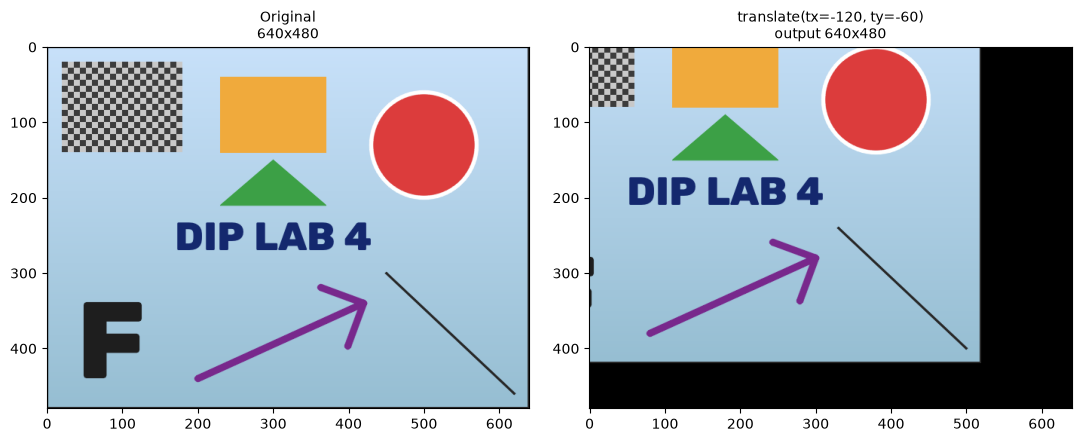

saved -> outputs\translate_tx-120_ty-60.png


In [22]:
r_t1 = demo("translate", "translate_tx80_ty40.png",    tx=80,   ty=40)      # right and down
r_t2 = demo("translate", "translate_tx-120_ty-60.png", tx=-120, ty=-60)     # left and up

**Observation – clipping and exposed background:** the canvas size is kept, so content pushed beyond an edge is **clipped** (lost – the first result loses the right 80 columns and bottom 40 rows, the second loses the left 120 columns and top 60 rows). The strip on the opposite side has no source pixels, so it is **exposed background** and is filled with black.

### 4.5 Rotation – positive and negative angles, with and without canvas expansion
A **positive angle rotates counter-clockwise** on screen, about the image centre.

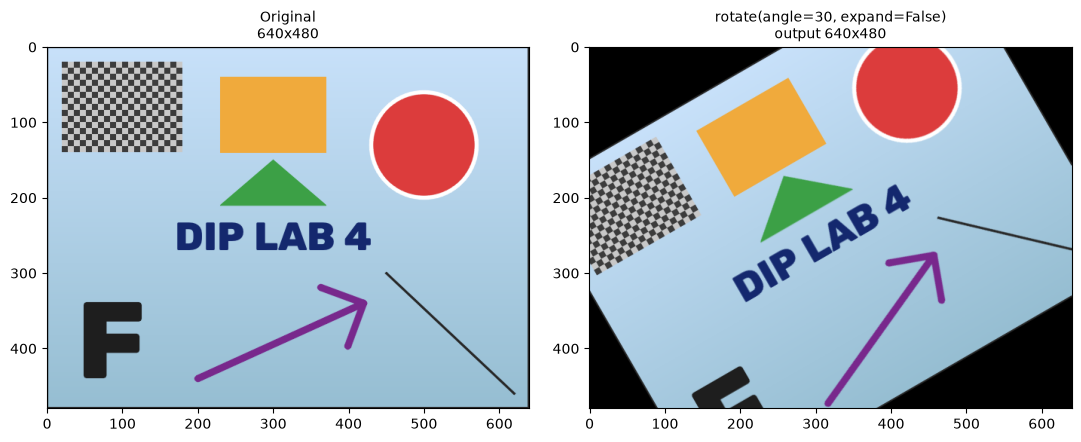

saved -> outputs\rotate_+30_noexpand.png


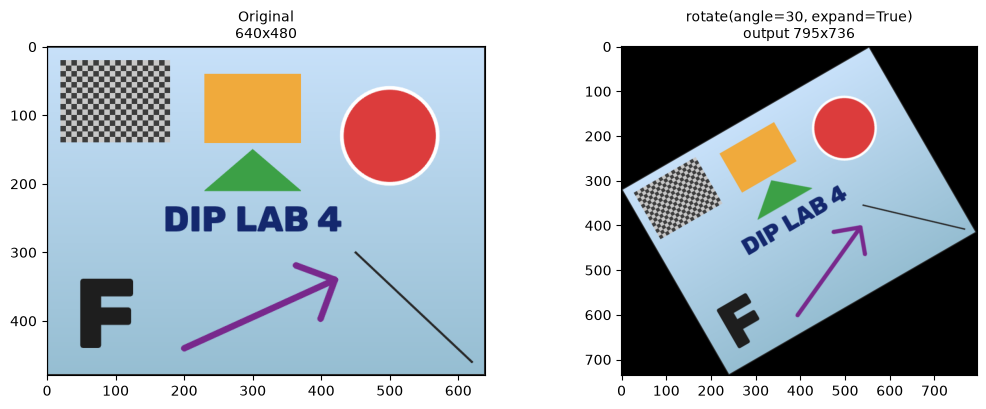

saved -> outputs\rotate_+30_expand.png


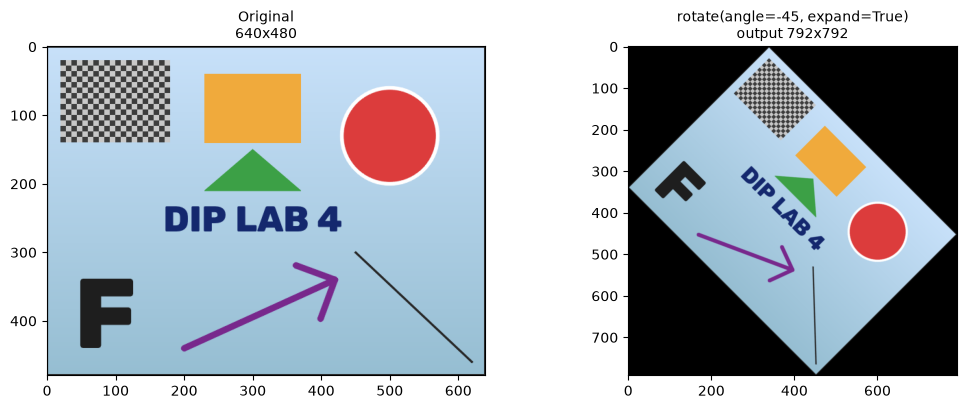

saved -> outputs\rotate_-45_expand.png


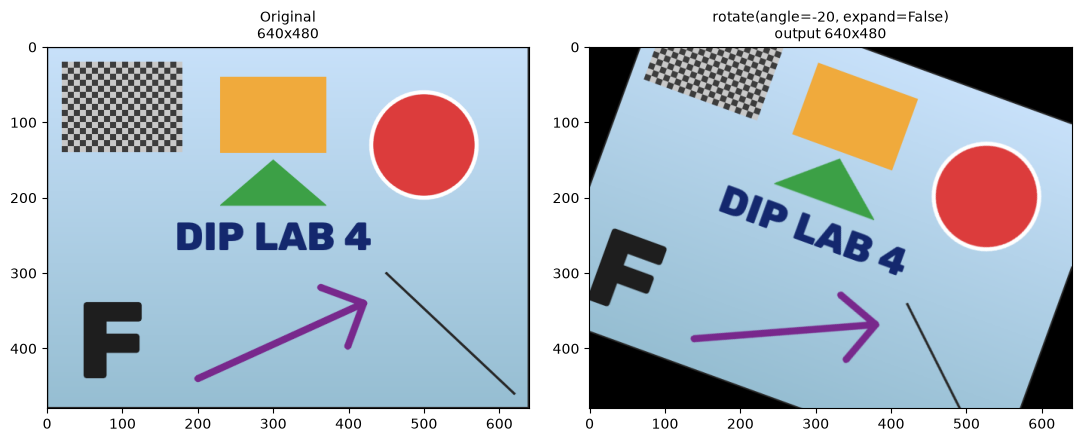

saved -> outputs\rotate_-20_noexpand.png


In [23]:
r_r1 = demo("rotate", "rotate_+30_noexpand.png", angle=30,  expand=False)
r_r2 = demo("rotate", "rotate_+30_expand.png",   angle=30,  expand=True)
r_r3 = demo("rotate", "rotate_-45_expand.png",   angle=-45, expand=True)
r_r4 = demo("rotate", "rotate_-20_noexpand.png", angle=-20, expand=False)

**Observation – canvas expansion:** with `expand=False` the canvas stays 640×480, so the rotated corners are cut off and black triangles appear. With `expand=True` the canvas grows to the bounding box of the rotated rectangle (see output sizes), nothing is cut off, and extra black corner areas are added. `+30°` turns the picture counter-clockwise (the arrow tilts further upward), `-45°` turns it clockwise.

## 5. Interpolation comparison on the same enlarged patch
A 40×30 patch from the checkerboard corner (squares are 8 px, grey levels 60 and 200) is enlarged **8×** with each method. Grey levels 60 and 200 are mid-tones on purpose, so any overshoot beyond them can be measured.

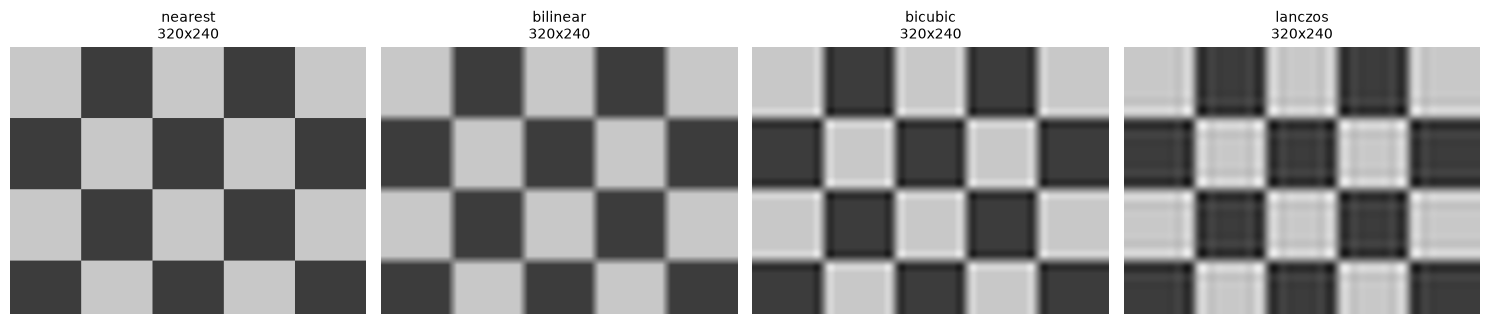

saved -> outputs\interp_nearest_patch_8x.png
saved -> outputs\interp_bilinear_patch_8x.png
saved -> outputs\interp_bicubic_patch_8x.png
saved -> outputs\interp_lanczos_patch_8x.png


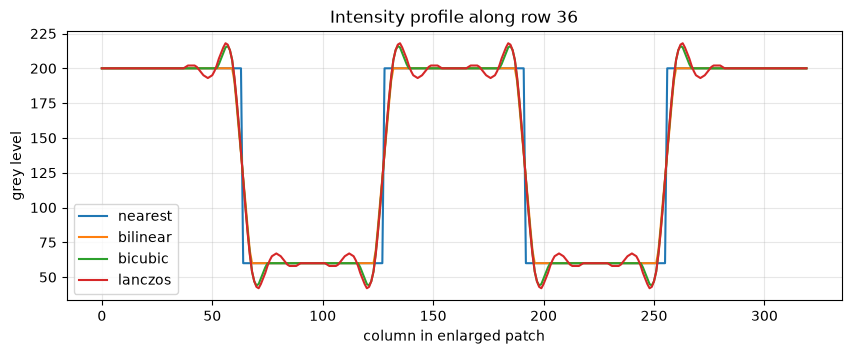

method     min  max  distinct levels   transition px per edge
nearest     60  200                2                      0.0
bilinear    60  200               30                      8.0
bicubic     26  234              116                      8.0
lanczos     21  239              158                     14.0


In [24]:
patch = transform(original, "crop", left=36, top=28, right=76, bottom=58)
methods = ["nearest", "bilinear", "bicubic", "lanczos"]
big = {m: transform(patch, "scale", sx=8, sy=8, interpolation=m) for m in methods}

fig, axes = plt.subplots(1, 4, figsize=(15, 3.8))
for ax, m in zip(axes, methods):
    ax.imshow(big[m]); ax.set_title(f"{m}\n{big[m].shape[1]}x{big[m].shape[0]}", fontsize=10); ax.axis("off")
plt.tight_layout(); plt.show()
for m in methods:
    save_image(big[m], f"interp_{m}_patch_8x.png")

# intensity profile along one row crossing four square edges
row = 36
plt.figure(figsize=(10, 3.5))
for m in methods:
    plt.plot(big[m][row, :, 0], label=m)
plt.xlabel("column in enlarged patch"); plt.ylabel("grey level"); plt.title(f"Intensity profile along row {row}")
plt.legend(); plt.grid(alpha=0.3); plt.show()

print(f"{'method':9s} {'min':>4s} {'max':>4s} {'distinct levels':>16s} {'transition px per edge':>24s}")
for m in methods:
    prof = big[m][row, :, 0].astype(int)
    trans = np.sum((prof > 65) & (prof < 195)) / 4          # pixels strictly between the two plateaus, 4 edges
    print(f"{m:9s} {big[m][:,:,0].min():4d} {big[m][:,:,0].max():4d} {len(np.unique(big[m][:,:,0])):16d} {trans:24.1f}")

**Observations (from the images, the intensity profile and the numbers above):**

* **Nearest-neighbour** creates no new grey levels (only 60 and 200). Edges stay perfectly sharp, but the result is blocky: every source pixel becomes an 8×8 block, which would look jagged on diagonals and curves.
* **Bilinear** gives smooth results with no new extremes (range stays 60–200), but every edge becomes a soft, blurred ramp.
* **Bicubic** looks sharper than bilinear but adds a thin bright/dark halo beside each edge (overshoot): values reach 26–234, outside the original 60–200.
* **Lanczos** has the strongest overshoot (21–239) and faint ripples ("ringing") inside the squares, so edges look crisp but with visible halos; it is also the most expensive to compute.

In short: nearest keeps hard edges but looks pixelated, bilinear is smooth but soft, and bicubic/Lanczos preserve detail best at the cost of halos near hard edges.

## 6. Rejected (invalid) inputs
Every case below is sent through the text layer (`apply_from_text`) or directly to `transform`; each must raise a `TransformError` with a clear message and must **not** crash the notebook.

In [25]:
def expect_rejection(operation, label, call):
    try:
        call()
    except TransformError as err:
        print(f"PASS  [{operation:9s}] {label}\n        -> rejected: {err}")
        return True
    except Exception as err:                                   # anything else would be an unhandled crash
        print(f"FAIL  [{operation:9s}] {label}\n        -> unexpected {type(err).__name__}: {err}")
        return False
    print(f"FAIL  [{operation:9s}] {label}\n        -> was ACCEPTED but should be rejected")
    return False

O = original
nan, inf = float("nan"), float("inf")
rejections = [
    # operation, description, callable
    ("scale",     "sx = 0",                              lambda: apply_from_text(O, "scale", {"sx": "0", "sy": "1", "interpolation": "bilinear"})),
    ("scale",     "sy = -2 (negative)",                  lambda: apply_from_text(O, "scale", {"sx": "1", "sy": "-2", "interpolation": "bilinear"})),
    ("scale",     "sx = 'abc' (non-numeric text)",       lambda: apply_from_text(O, "scale", {"sx": "abc", "sy": "1", "interpolation": "bilinear"})),
    ("scale",     "sx = NaN passed directly",            lambda: transform(O, "scale", sx=nan, sy=1, interpolation="bilinear")),
    ("scale",     "unsupported interpolation 'spline'",  lambda: apply_from_text(O, "scale", {"sx": "2", "sy": "2", "interpolation": "spline"})),
    ("scale",     "sx = 0.0001 -> width would be 0 px",  lambda: apply_from_text(O, "scale", {"sx": "0.0001", "sy": "1", "interpolation": "nearest"})),
    ("scale",     "sx = sy = 7 -> exceeds maximum size", lambda: apply_from_text(O, "scale", {"sx": "7", "sy": "7", "interpolation": "bilinear"})),
    ("scale",     "interpolation missing (no default)",  lambda: transform(O, "scale", sx=2, sy=2)),
    ("crop",      "right <= left (100, 80)",             lambda: apply_from_text(O, "crop", {"left": "100", "top": "0", "right": "80", "bottom": "100"})),
    ("crop",      "right = 700 > width 640",             lambda: apply_from_text(O, "crop", {"left": "0", "top": "0", "right": "700", "bottom": "100"})),
    ("crop",      "negative left = -5",                  lambda: apply_from_text(O, "crop", {"left": "-5", "top": "0", "right": "100", "bottom": "100"})),
    ("crop",      "non-integer coordinate 10.5",         lambda: apply_from_text(O, "crop", {"left": "10.5", "top": "0", "right": "100", "bottom": "100"})),
    ("crop",      "bottom missing",                      lambda: transform(O, "crop", left=0, top=0, right=10)),
    ("flip",      "unsupported direction 'diagonal'",    lambda: apply_from_text(O, "flip", {"direction": "diagonal"})),
    ("flip",      "direction = None",                    lambda: transform(O, "flip", direction=None)),
    ("translate", "tx = 'abc' (non-numeric text)",       lambda: apply_from_text(O, "translate", {"tx": "abc", "ty": "0"})),
    ("translate", "tx = 'nan' text",                     lambda: apply_from_text(O, "translate", {"tx": "nan", "ty": "0"})),
    ("translate", "ty = infinity passed directly",       lambda: transform(O, "translate", tx=0, ty=inf)),
    ("translate", "ty missing",                          lambda: transform(O, "translate", tx=5)),
    ("rotate",    "angle = 'abc' (non-numeric text)",    lambda: apply_from_text(O, "rotate", {"angle": "abc", "expand": "yes"})),
    ("rotate",    "angle = 'inf' text",                  lambda: apply_from_text(O, "rotate", {"angle": "inf", "expand": "yes"})),
    ("rotate",    "angle = NaN passed directly",         lambda: transform(O, "rotate", angle=nan, expand=True)),
    ("rotate",    "expand = 'maybe'",                    lambda: apply_from_text(O, "rotate", {"angle": "10", "expand": "maybe"})),
    ("rotate",    "expand = 'yes' string passed directly", lambda: transform(O, "rotate", angle=10, expand="yes")),
    ("(general)", "unknown operation 'shear'",           lambda: transform(O, "shear", k=1)),
    ("(general)", "invalid image (None)",                lambda: transform(None, "flip", direction="both")),
]
rej_results = [expect_rejection(*row) for row in rejections]
print(f"\n{sum(rej_results)} of {len(rej_results)} invalid inputs were rejected correctly.")

PASS  [scale    ] sx = 0
        -> rejected: scale factors must be greater than zero, got sx=0.0, sy=1.0
PASS  [scale    ] sy = -2 (negative)
        -> rejected: scale factors must be greater than zero, got sx=1.0, sy=-2.0
PASS  [scale    ] sx = 'abc' (non-numeric text)
        -> rejected: sx: 'abc' is not a number
PASS  [scale    ] sx = NaN passed directly
        -> rejected: sx must be finite (NaN and infinity are not allowed), got nan
PASS  [scale    ] unsupported interpolation 'spline'
        -> rejected: interpolation must be one of ['nearest', 'bilinear', 'bicubic', 'lanczos'], got 'spline'
PASS  [scale    ] sx = 0.0001 -> width would be 0 px
        -> rejected: output would be 0x480; both dimensions must be at least 1 pixel
PASS  [scale    ] sx = sy = 7 -> exceeds maximum size
        -> rejected: output 4480x3360 exceeds the limit (max side 4000px, max 12,000,000 pixels)
PASS  [scale    ] interpolation missing (no default)
        -> rejected: 'scale' is missing required 

### Valid boundary inputs must still be accepted
Zero values, negative values and the exact limits are legal and must **not** be rejected.

In [26]:
boundary = [
    ("crop whole image (0,0,640,480)",   lambda: transform(O, "crop", left=0, top=0, right=640, bottom=480), (480, 640, 3)),
    ("crop a single pixel",              lambda: transform(O, "crop", left=0, top=0, right=1, bottom=1),     (1, 1, 3)),
    ("scale to exactly 1 px wide",       lambda: transform(O, "scale", sx=1/640, sy=1, interpolation="nearest"), (480, 1, 3)),
    ("translate tx=-50, ty=0 (neg/zero)", lambda: transform(O, "translate", tx=-50, ty=0),                    (480, 640, 3)),
    ("translate tx=0.5, ty=-0.5 (fractional)", lambda: transform(O, "translate", tx=0.5, ty=-0.5),           (480, 640, 3)),
    ("rotate angle=-720, expand=False",  lambda: transform(O, "rotate", angle=-720, expand=False),            (480, 640, 3)),
    ("rotate angle=90, expand=True",     lambda: transform(O, "rotate", angle=90, expand=True),               (640, 480, 3)),
]
for label, call, expected_shape in boundary:
    got = call().shape
    print(f"{'PASS' if got == expected_shape else 'FAIL'}  {label:42s} -> shape {got} (expected {expected_shape})")

PASS  crop whole image (0,0,640,480)             -> shape (480, 640, 3) (expected (480, 640, 3))
PASS  crop a single pixel                        -> shape (1, 1, 3) (expected (1, 1, 3))
PASS  scale to exactly 1 px wide                 -> shape (480, 1, 3) (expected (480, 1, 3))
PASS  translate tx=-50, ty=0 (neg/zero)          -> shape (480, 640, 3) (expected (480, 640, 3))
PASS  translate tx=0.5, ty=-0.5 (fractional)     -> shape (480, 640, 3) (expected (480, 640, 3))
PASS  rotate angle=-720, expand=False            -> shape (480, 640, 3) (expected (480, 640, 3))
PASS  rotate angle=90, expand=True               -> shape (640, 480, 3) (expected (640, 480, 3))


## 7. Identity checks
Zero translation, scale factors of one and zero rotation must leave the image unchanged (same shape and identical pixels).

In [27]:
identity_cases = [
    ("translate tx=0, ty=0",            "translate", dict(tx=0, ty=0)),
    ("translate tx=0.0, ty=-0.0",       "translate", dict(tx=0.0, ty=-0.0)),
    ("scale 1x1, nearest",              "scale",     dict(sx=1, sy=1, interpolation="nearest")),
    ("scale 1x1, bilinear",             "scale",     dict(sx=1, sy=1, interpolation="bilinear")),
    ("scale 1x1, bicubic",              "scale",     dict(sx=1, sy=1, interpolation="bicubic")),
    ("scale 1x1, lanczos",              "scale",     dict(sx=1, sy=1, interpolation="lanczos")),
    ("rotate 0 deg, expand=False",      "rotate",    dict(angle=0, expand=False)),
    ("rotate 0 deg, expand=True",       "rotate",    dict(angle=0, expand=True)),
    ("rotate -0.0 deg, expand=False",   "rotate",    dict(angle=-0.0, expand=False)),
    ("rotate 360 deg, expand=False",    "rotate",    dict(angle=360, expand=False)),
]
rows = []
for name, op, params in identity_cases:
    out = transform(original, op, **params)
    same_shape = out.shape == original.shape
    max_diff = int(np.abs(out.astype(int) - original.astype(int)).max()) if same_shape else -1
    ok = same_shape and max_diff == 0
    rows.append((name, "same shape, identical pixels", f"shape {out.shape[1]}x{out.shape[0]}, max pixel diff {max_diff}", "Pass" if ok else "Fail"))

headers = ("Check", "Expected", "Actual", "Result")
widths = [max(len(str(r[i])) for r in rows + [headers]) for i in range(4)]
line = lambda r: " | ".join(str(c).ljust(w) for c, w in zip(r, widths))
print(line(headers)); print("-+-".join("-" * w for w in widths))
for r in rows: print(line(r))
print(f"\n{sum(r[3] == 'Pass' for r in rows)} of {len(rows)} identity checks passed.")

Check                         | Expected                     | Actual                          | Result
------------------------------+------------------------------+---------------------------------+-------
translate tx=0, ty=0          | same shape, identical pixels | shape 640x480, max pixel diff 0 | Pass  
translate tx=0.0, ty=-0.0     | same shape, identical pixels | shape 640x480, max pixel diff 0 | Pass  
scale 1x1, nearest            | same shape, identical pixels | shape 640x480, max pixel diff 0 | Pass  
scale 1x1, bilinear           | same shape, identical pixels | shape 640x480, max pixel diff 0 | Pass  
scale 1x1, bicubic            | same shape, identical pixels | shape 640x480, max pixel diff 0 | Pass  
scale 1x1, lanczos            | same shape, identical pixels | shape 640x480, max pixel diff 0 | Pass  
rotate 0 deg, expand=False    | same shape, identical pixels | shape 640x480, max pixel diff 0 | Pass  
rotate 0 deg, expand=True     | same shape, identical pixels | s

## 8. Explanations

**Image coordinates vs array indexing.** In image (Cartesian-style) coordinates a point is written **(x, y)**: *x* runs to the right along the width, *y* runs **downwards** along the height, and the origin (0, 0) is the **top-left** corner. A NumPy array is indexed **[row, column] = [y, x]**, and its shape is **(height, width, channels)**. So the pixel at x=100, y=50 is `image[50, 100]`, and a crop is `image[top:bottom, left:right]`. Mixing up the two orders is a common bug (`image.shape` gives height first, but OpenCV functions such as `cv2.resize` and `cv2.warpAffine` take sizes as **(width, height)**).

**Aspect-ratio distortion.** The aspect ratio is width ÷ height. It is preserved only when `sx == sy`. With different factors (e.g. `sx=2.0, sy=0.5`) the picture is stretched more in one direction, so circles become ellipses and text looks squeezed or widened.

**Rotation canvas expansion.** Rotating a rectangle by an angle that is not a multiple of 90° makes it extend beyond the original canvas. With `expand=False` the canvas size is kept, so the corners are clipped. With `expand=True` the new canvas is the bounding box of the rotated rectangle, `w·|cos θ| + h·|sin θ|` by `w·|sin θ| + h·|cos θ|`, so nothing is lost; the extra corners are filled with black. The rotation is about the image centre, and a positive angle is counter-clockwise on screen.

**Translation clipping.** Translation keeps the canvas size. Pixels pushed past an edge are **clipped** (discarded), and the opposite edge has no source pixels, so a strip of **exposed background** (black) appears. Translating back would not restore the lost pixels.

## 9. Final checks and saved files

In [28]:
assert np.array_equal(original, original_backup), "original image was modified!"
print("Original image is unchanged: OK")
print(f"\nSaved transformed images in '{OUTPUT_DIR}/':")
for f in sorted(os.listdir(OUTPUT_DIR)):
    print("  ", f)

Original image is unchanged: OK

Saved transformed images in 'outputs/':
   .gitignore
   crop_left100_top50_right420_bottom330.png
   crop_letterF.png
   flip_both.png
   flip_horizontal.png
   flip_vertical.png
   interactive_1_rotate.png
   interactive_2_crop.png
   interactive_3_flip.png
   interactive_4_scale.png
   interactive_5_translate.png
   interp_bicubic_patch_8x.png
   interp_bilinear_patch_8x.png
   interp_lanczos_patch_8x.png
   interp_nearest_patch_8x.png
   rotate_+30_expand.png
   rotate_+30_noexpand.png
   rotate_-20_noexpand.png
   rotate_-45_expand.png
   scale_enlarge_1.5x_bicubic.png
   scale_nonproportional_2x_0.5y.png
   scale_reduce_0.5x_bilinear.png
   translate_tx-120_ty-60.png
   translate_tx80_ty40.png
